In [14]:
import time
import sys
import os

# Add the parent directory to sys.path
notebook_path = os.getcwd()  # Get the current working directory where the notebook is located
parent_directory = os.path.dirname(notebook_path)  # Move to the parent directory
sys.path.append(parent_directory)

# Now you can import config
from config import *
#from Minimal_Model_2D import *
import Minimal_Model_2D as mm2d
import time

np.set_printoptions(threshold=sys.maxsize)

In [15]:
NSM = 60            # number of sm x lattice points
M = 60              # should be atleast thrice confinement length
AX = 5              # lattice spacing in nm
AY = 5              # lattice spacing in nm
DELTA = 0.165       # in meV
MEFF_SC = 0.023     # proximitized InAs
MEFF_SM = 0.023     # InAs
NSC = 800
NTOT = 2*NSC + NSM
PHI = 0.5*np.pi 
ALPHAT = 20        # meV-nm^3 # 20 is within perturbative regime for widths atleast up to 100 nm
K_NUM = 8           # No of eigenvalues needed to be found 
#W_MIN = 50

LY = 100           # Width in nm
OMEGA = 2*4*hbm/LY**2/MEFF_SC

MY= 5 

print('lengths=', M*AY, LY)
OMEGA = 2*4*hbm/LY**2/MEFF_SC

print('subband energies=', OMEGA/2, 3*OMEGA/2)

print('4t=', 4*hbm/AX**2/MEFF_SM)

MU_SC =   OMEGA/2 +OMEGA/10  # in between two subbands - such that we get two abs prferably 
MU_SM =   OMEGA/2 +OMEGA/10  # in between two subbands - such that we get two abs prferably

print('mu = ', MU_SM)


UNCORR_VAR = 0  ### uncorrelated variance of disorder
LMBDA = 0
SEED = 58  ## seed for the disorder

ModCT = mm2d.twoD_Minimal_Model(NTOT, NSM, NSC, M, AX, AY, OMEGA, ALPHAT, DELTA, MEFF_SC, MEFF_SM, MU_SC, MU_SM)

lengths= 300 100
subband energies= 0.6631720133634798 1.9895160400904393
4t= 265.2688053453919
mu =  0.7958064160361757


In [16]:
XCT = (NSC+NSM/2)*AX
YCT = np.linspace(-200*AY,(M+200)*AY,51)
ZCT = 50
ZIM = 64

print('X co-ordinate of charge trap =', XCT )

Ep = np.empty((YCT.shape[0],K_NUM))

for i in range(YCT.shape[0]):

    H = ModCT.H_sys(PHI, 'li', XCT, YCT[i], ZCT, ZIM)

    E = eigsh(H, k=K_NUM, sigma=0, return_eigenvectors=False )

    Es = np.sort(E)/DELTA

    Ep[i,:] = Es

    if i%5==0:
        print(Ep[i,:])

np.save('linear_E_vs_yct_Zdiff_{}_wider_yct.npy'.format(ZIM-ZCT), Ep)

X co-ordinate of charge trap = 4150.0
[-0.89260299 -0.88934776 -0.35798098 -0.35600524  0.35600524  0.35798098
  0.88934776  0.89260299]
[-0.8925236  -0.8892689  -0.35797269 -0.3559973   0.3559973   0.35797269
  0.8892689   0.8925236 ]
[-0.89230275 -0.88904955 -0.35794778 -0.35597336  0.35597336  0.35794778
  0.88904955  0.89230275]
[-0.89141376 -0.88816684 -0.35782672 -0.3558563   0.3558563   0.35782672
  0.88816684  0.89141376]
[-0.88322207 -0.88004445 -0.35574349 -0.3538135   0.3538135   0.35574349
  0.88004445  0.88322207]
[-0.76823626 -0.76737605 -0.36155561 -0.36089909  0.36089909  0.36155561
  0.76737605  0.76823626]
[-0.88197013 -0.87880415 -0.35530465 -0.35338109  0.35338109  0.35530465
  0.87880415  0.88197013]
[-0.89132919 -0.88808287 -0.35781373 -0.35584368  0.35584368  0.35781373
  0.88808287  0.89132919]
[-0.89228582 -0.88903274 -0.35794577 -0.35597142  0.35597142  0.35794577
  0.88903274  0.89228582]
[-0.89251822 -0.88926356 -0.35797212 -0.35599675  0.35599675  0.3579721

In [25]:
#XCT = np.linspace((NSC-10)*AX, (NSC+NSM+10)*AX, 21)
#YCT = M/2*AY
#Ep = np.load("C:\\Users\\Vivrekar\\Desktop\\Spin_Splitting_Ge_ABS\\disorder_charge_trap\\linear_E_vs_xct_Zdiff_0.20000000000000284.npy")


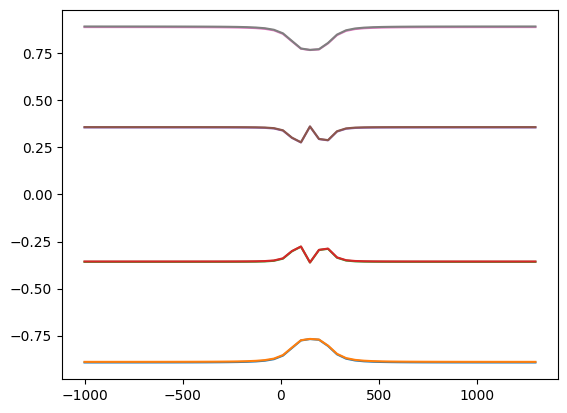

In [17]:
plt.plot(YCT, Ep[:, :])
#plt.axvline(x=NSC*AX, color='black', linestyle='dotted')
#plt.axvline(x=(NSC+NSM-1)*AX, color='black', linestyle='dotted')

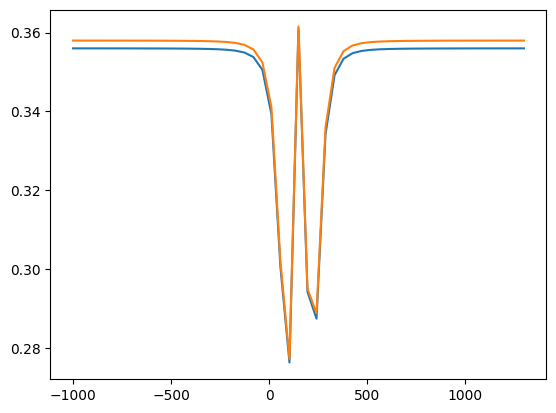

In [18]:
plt.plot(YCT, Ep[:, K_NUM//2:K_NUM//2+2])
#plt.axvline(x=NSC*AX, color='black', linestyle='dotted')
#plt.axvline(x=(NSC+NSM-1)*AX, color='black', linestyle='dotted')

(0.0, 0.0020416984392235132)

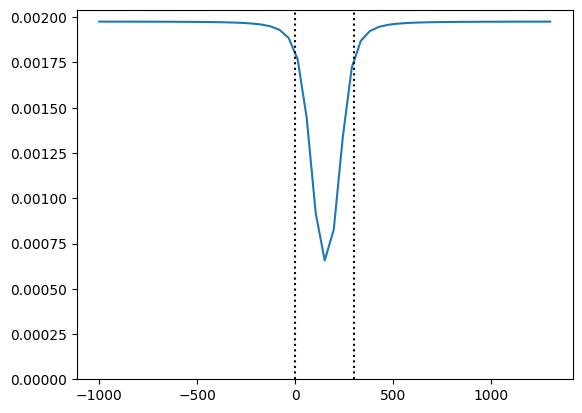

In [20]:
plt.plot(YCT, Ep[:, K_NUM//2+1]-Ep[:, K_NUM//2])

plt.axvline(x=0, color='black', linestyle='dotted')
plt.axvline(x=M*AY, color='black', linestyle='dotted')
plt.ylim(ymin=0)

#plt.ylim(ymin=0,ymax = 1.2*np.max(Ep[:, K_NUM//2+1]-Ep[:, K_NUM//2]))

(0.0, 0.0018683361753603384)

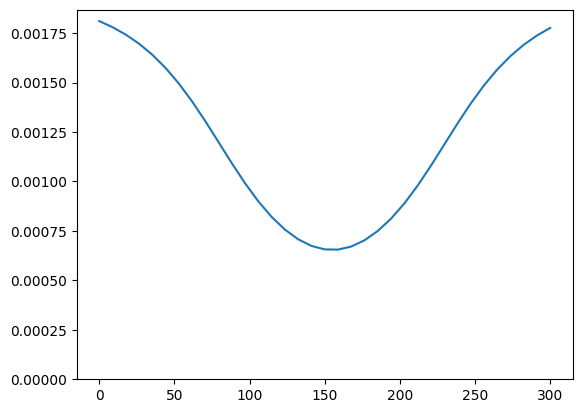

In [13]:
plt.plot(YCT, Ep[:, K_NUM//2+1]-Ep[:, K_NUM//2])
plt.ylim(ymin=0)
#plt.axvline(x=NSC*AX, color='black', linestyle='dotted')
#plt.axvline(x=(NSC+NSM-1)*AX, color='black', linestyle='dotted')

#plt.ylim(ymin=0,ymax = 1.2*np.max(Ep[:, K_NUM//2+1]-Ep[:, K_NUM//2]))

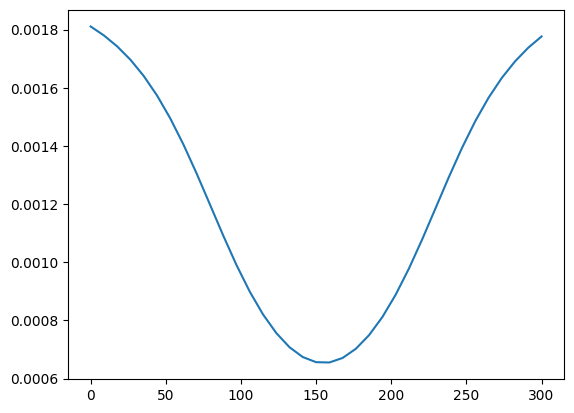

In [12]:
plt.plot(YCT, Ep[:, K_NUM//2+1]-Ep[:, K_NUM//2])
#plt.axvline(x=NSC*AX, color='black', linestyle='dotted')
#plt.axvline(x=(NSC+NSM-1)*AX, color='black', linestyle='dotted')
#plt.ylim(ymin=0,ymax = 1.2*np.max(Ep[:, K_NUM//2+1]-Ep[:, K_NUM//2]))

In [9]:
linear_spin_split = Ep[:, K_NUM//2+1]-Ep[:, K_NUM//2] 

min_spin_split = np.min(linear_spin_split)

max_spin_split = np.max(linear_spin_split)

percent_spin_split = (max_spin_split-min_spin_split)/max_spin_split

print(percent_spin_split)

0.7059000927567326


In [13]:
XCT = np.linspace((NSC-10)*AX, (NSC+NSM+10)*AX, 21)
YCT = M/2*AY
Ep = np.load("C:\\Users\\Vivrekar\\Desktop\\Spin_Splitting_Ge_ABS\\disorder_charge_trap\\linear_E_vs_xct_V1.npy")

(0.0, 0.0023691305210776113)

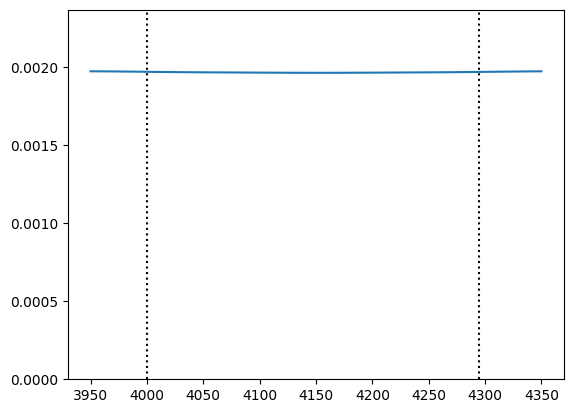

In [14]:
plt.plot(XCT, Ep[:, K_NUM//2+1]-Ep[:, K_NUM//2])
plt.axvline(x=NSC*AX, color='black', linestyle='dotted')
plt.axvline(x=(NSC+NSM-1)*AX, color='black', linestyle='dotted')
plt.ylim(ymin=0,ymax = 1.2*np.max(Ep[:, K_NUM//2+1]-Ep[:, K_NUM//2]))